In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [3]:
df = pd.read_csv("../data/steam-200k.csv", header=None, names=['id', 'game', 'behavior', 'value','unused'])
print(f"проверка пропусков:\n{df.isna().sum()}\n")
print(f"количество уникальных пользователей:{df["id"].nunique()}")
print(f"количество уникальных игр:{df["game"].nunique()}\n")
print(f"{df["behavior"].value_counts()}")

проверка пропусков:
id          0
game        0
behavior    0
value       0
unused      0
dtype: int64

количество уникальных пользователей:12393
количество уникальных игр:5155

behavior
purchase    129511
play         70489
Name: count, dtype: int64


In [4]:
rating_game_10 = df[df["behavior"] == 'purchase'].groupby("game").nunique().sort_values(by=["id"],ascending=False).head(10)
rating_game_10

,id,behavior,value,unused
game,,,,
Dota 2,4841,1,1,1
Team Fortress 2,2323,1,1,1
Unturned,1563,1,1,1
Counter-Strike Global Offensive,1412,1,1,1
Half-Life 2 Lost Coast,981,1,1,1
Counter-Strike Source,978,1,1,1
Left 4 Dead 2,951,1,1,1
Counter-Strike,856,1,1,1
Warframe,847,1,1,1


In [5]:
df[df["behavior"] == 'play']["value"].describe()

count    70489.000000
mean        48.878063
std        229.335236
min          0.100000
25%          1.000000
50%          4.500000
75%         19.100000
max      11754.000000
Name: value, dtype: float64

(array([1.4285e+04, 9.3770e+03, 8.3440e+03, 6.9420e+03, 6.3750e+03,
        6.1310e+03, 4.9070e+03, 3.6870e+03, 3.0110e+03, 2.1660e+03,
        1.5860e+03, 1.2070e+03, 8.4900e+02, 6.6400e+02, 4.7200e+02,
        2.7400e+02, 1.3500e+02, 5.0000e+01, 2.3000e+01, 4.0000e+00]),
 array([0.09531018, 0.55914637, 1.02298256, 1.48681875, 1.95065494,
        2.41449113, 2.87832731, 3.3421635 , 3.80599969, 4.26983588,
        4.73367207, 5.19750826, 5.66134445, 6.12518064, 6.58901683,
        7.05285302, 7.5166892 , 7.98052539, 8.44436158, 8.90819777,
        9.37203396]),
 <BarContainer object of 20 artists>)

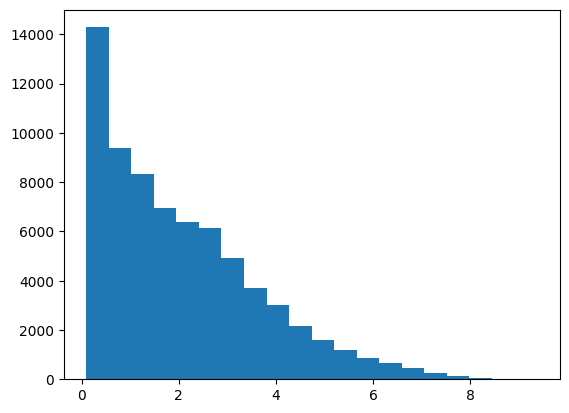

In [6]:
plt.hist(x = np.log1p(df[df["behavior"] == 'play']["value"]), bins = 20)

In [9]:
df[df["behavior"] == "purchase"].groupby("id")["game"].nunique().describe()

count    12393.000000
mean        10.393287
std         35.635890
min          1.000000
25%          1.000000
50%          2.000000
75%          6.000000
max       1068.000000
Name: game, dtype: float64

(array([5.700e+03, 1.476e+03, 0.000e+00, 8.270e+02, 6.330e+02, 8.400e+02,
        2.580e+02, 4.700e+02, 4.120e+02, 2.640e+02, 2.480e+02, 2.000e+02,
        1.890e+02, 1.570e+02, 1.400e+02, 1.110e+02, 8.800e+01, 7.500e+01,
        7.800e+01, 7.000e+01, 4.600e+01, 4.000e+01, 1.900e+01, 1.700e+01,
        9.000e+00, 1.200e+01, 6.000e+00, 5.000e+00, 2.000e+00, 1.000e+00]),
 array([0.69314718, 0.9025249 , 1.11190263, 1.32128035, 1.53065808,
        1.7400358 , 1.94941353, 2.15879125, 2.36816898, 2.5775467 ,
        2.78692442, 2.99630215, 3.20567987, 3.4150576 , 3.62443532,
        3.83381305, 4.04319077, 4.25256849, 4.46194622, 4.67132394,
        4.88070167, 5.09007939, 5.29945712, 5.50883484, 5.71821256,
        5.92759029, 6.13696801, 6.34634574, 6.55572346, 6.76510119,
        6.97447891]),
 <BarContainer object of 30 artists>)

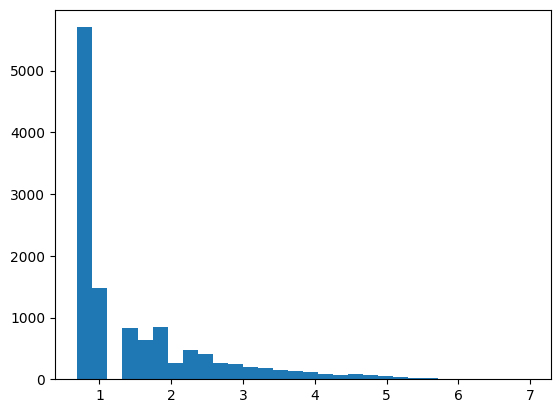

In [12]:
plt.hist(x = np.log1p(df[df["behavior"] == "purchase"].groupby("id")["game"].nunique()), bins = 30)

In [22]:
df[df["behavior"] == "purchase"].groupby("id")["game"].nunique().value_counts(normalize=True).loc[1]

np.float64(0.45993706124425077)

In [23]:
a = 0.459937 * 100
a

45.9937